<a href="https://colab.research.google.com/github/qhtni/CB2330-project/blob/main/PRO1_Group8_2330.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


---

#**Project CB2330:** *- Predicting Severe Coral Bleaching Events with a GLMM: replacing calendar time with climate parameters to improve model performance*

---




#**Project card**

---
# The paper

Terry P. Hughes et al., Spatial and temporal patterns of mass bleaching of corals in the Anthropocene. *Science* **359**, 80-83 (2018).
[DOI: 10.1126/science.aan8048](https://www.science.org/doi/10.1126/science.aan8048)

---
# What the paper does

The researchers noted bleaching events (severe, moderate, or nothing) across 4 regions (100 specific locations in total) from 1980 - 2016.


For their temporal models, bleaching was represented either as severe bleaching alone (severe = 1, moderate and none each = 0) or as all bleaching events (severe and moderate each = 1, none = 0) and region-specific changes through time were estimated.

They use a Generalized Linear Mixed Model to answer these two questions. They mention how temperature is going up over time and how climate phases (el Niño and la Niña) are converging, but their GLMM uses only Region and Time (years since 1980) as fixed effects. Their random effect is specified by individual locations (within regions).

Their general conclusion was that coral bleaching is occurring more frequently in all El Niño–Southern Oscillation (ENSO) phases and is increasing the likelihood of annual bleaching in the future.

---
# The random variable chosen

We aimed to build on their model and answer:

- *Instead of using time alone to describe the increase in severe bleaching, could measured annual global temperature and Niño 3.4 variation better reproduce the observed bleaching pattern?*


Therefore, our random variable is $Y_{igt}$ which represents the occurrence of severe coral bleaching at a reef *i*, in region *g*, during year *t*.


It is a binary variable where:

$Y_{igt}=1$ → Severe bleaching occured

$Y_{igt}=0$ → No severe bleaching occurred (either moderate or no bleaching occurred).


The variable follows a Bernoulli distribution with probability *$p_{igt}$* :

 $$(Y_ {igt}\sim \text{Bernoulli}(p_{igt}))$$

---
# The generative model proposed

Since climate factors are only briefly mentioned in the article and their model focuses mostly on Time, we wanted to investigate the possibility of improving the model's fit by introducing specific climate predictors. While their model is able to capture long term trends, we wanted to see whether we could try and fit the data to match the "cyclical" nature of severe bleaching events that coincide with el Niño and la Niña phases.

The proposed model for this project is thus a modified version of their GLMM, where Region remains a fixed effect ($\beta_0$) and their Time predictor is replaced by Annual Global Temperature Anomalies ($ G_t$ ), and Annual Niño 3.4 Anomalies ($N_t$). Anomalies in this case are the increase or decrease from the mean annual value of that variable each year shows.The $\beta$ values represent the weights of each of these independent variables and how they contribute to the probability of a severe bleaching event occuring. Each specific location is used as a random effect ($r_i$) as the researchers did.

$$
\mathrm{logit}(p_{igt}) = \beta_{0,g} + \beta_{1,g}G_t + \beta_{2,g}N_t + r_i
$$

A GLMM allows us to model the probability of binary variables since our probability (on the left side of the equation) is no longer restricted to values between 0 and 1. Logit(p) uses log-odds to allow for values between -∞ and +∞ where p can still be calculated using the inverse logit:

$$
Z_{igt} = \beta_{0,g} + \beta_{1,g}G_t + \beta_{2,g}N_t + r_i
$$

$$
p_{igt} = \frac{1}{1+e^{-Z}}
$$

The probability can then be used to predict a bleaching event which is how we come back to:

$$(Y_ {igt}\sim \text{Bernoulli}(p_{igt}))$$


**More information on the model can be found later in the notebook (where random effect is described in better detail as well)

---
# Parameters and assumptions


##**<u>Our model - Parameters</u>**

**Fixed effects:**

$\beta_0$ is the regional baseline log-odds of severe bleaching at mean climate conditions.

$\beta_{1,g}$ is a regional-dependent coefficient that represents the effect/weight of global temperature anomalies ($G_t$) on the chance of a severe bleaching event. (log-odds per +1°C change in centered global temperature anomaly)

$\beta_{2,g}$ is a regional-dependent coefficient that represents the effect/weight of Niño 3.4 anomalies ($N_t$) on the chance of a severe bleaching event. (log-odds per +1°C change in centered Niño 3.4 anomaly)

$N_t$ centered annual mean Niño 3.4 temperature anomaly in °C

$G_t$ centered annual mean global temperature anomaly in °C

(Both variables are centered so that their average across 1980–2016 is 0, focusing on the study period)

**Random effect:**

$r_i$ is the random intercept for reef *i*. It is the standard deviation of reef random intercepts on the log-odds scale. It considers the variance shown at an individual level where:

$$r_i \sim N(0, \sigma^2_{\mathrm{reef}})$$

This is how the random effect is modelled in a GLMM and more information can be found on it later in the notebook and in our assumptions (se point 5 (4.5) under "More detailed ones").

##**<u>Assumptions</u>**

Major ones:
1. Severe bleaching is a Bernoulli event.
2. Global temperature and Niño affect bleaching log-odds linearly within each region.
3. Reef-to-reef differences are constant through time and normally distributed.
4. Annual global climate variables are sufficient proxies for other potential predictors.

More detailed ones:
1. A binary variable is appropriate for characterizing severe bleaching. We are not using a continuous variable such as percentage of area bleached and assume that a binary variable is enough to explore our question.
2. The relationship between our climate predictors (specifically G and N)and the log-odds of severe bleaching is linear.
3. Each of the four regions is allowed its own intercept ($\beta_0$), global temperature effect ($\beta_{1,g}$), and Niño effect ($\beta_{2,g}$), but reefs within the same region share those fixed effect coefficients.
4. Reef differences can actually be captured by the random effect. So each reef has a persistent tendency to be more or less susceptible than average, represented by ($r_i$).
5. (4.5) Random reef effects are normally distributed. The ($r_i$) values are assumed to come from a normal distribution centered at zero. This is how a random effect is described in a GLMM. We also assume that this value does not change over the years.
6. Annual climate summaries are adequate predictors. We assume annual mean global temperature anomaly and annual mean Niño 3.4 anomaly contain useful information about bleaching risk, even though bleaching often depends on shorter extreme heat events. Using means smooths out the data in a sense but we hope that it still shows short-term effects better than the researchers' model.
7. We assume there is no delayed effect, or accumulated heat stress process.
8. We assume our predictors are a proxy for things like depth, species, local pollution, adaptation, storms, and recovery. They are only indirectly considered through the reef random effect.

---

# The data object(s)

The primary dataset is derived from the paper and consists of registered coral bleaching events between 1980 to 2016. (It can be found in /data under the GitHub repository, or by clicking [here](https://github.com/qhtni/CB2330-project/blob/main/data/coral_data.xlsx))

It contains one row per reef location per year in four different regions (Australasia, Indian Ocean, the Pacific and the Western Atlantic). This dataset is the origin of the chosen random variable in this project (the occurrence of severe bleaching; severe = 1, moderate = 0, none = 0).

Additionally, in order to improve the original model (the goal of this project), which relied on calendar time as a primary predictor, an external dataset was gathered. The ENSO forecast dataset (which can be found in /data under the GitHub repository, or by clicking [here](https://github.com/qhtni/CB2330-project/blob/main/data/dataset_enso_2026.csv)) provided additional data that was needed in order to introduce climate specific predictors.

## Our data object

From these two datasets a third dataset was created, containing the relevant data (listed below) required to run the code presented in this project. (It can be found under /data under the GitHub respository, or by clicking [here](https://github.com/qhtni/CB2330-project/blob/main/data/master_location_year.csv))


Three main predictors go into our model, with two of them being different from the researchers' model. While their fixed effects were Region and Time (years since 1980), we suggested a model with Region, Annual Global Temperature Anomaly, and Annual el Niño 3.4 Temperature Anomaly. These two new climate predictors replace the article's time predictor that they implied was climate related but provided no numerical substantiation. By rewriting the article's original model and using these predictors instead, the ambition was to improve the model's fit towards the random variable (severe bleaching events).

###Explaination of the columns in the dataset:

**From the article:**

`location_id`: Specific reef location id (1-100)

`region`: Region the location belongs to

`year`: Year the data was collected

`t`: Years since 1980

`severe`: Equal to 1 if there was a severe event, 0 for anything else


**From the ENSO dataset:**

`global_temp_anom_mean`: annual global temperature anomaly mean in °C
`nino34_anom_mean`: annual Niño 3.4 anomaly mean in °C
`temp_c`: centered annual global temperature anomaly in °C
`nino_c`: centered annual mean Niño 3.4 anomaly in °C

**It is important to note that we are using the centered variables for our work (they are centered to the study period). The annual means are simply in the table still for reference in case something was off. So both variables are centered so that their average across 1980–2016 is 0.

---
# The parameterization/fitting

We use the coefficients from the glmer() function in R to run one observation across all years for all the locations. So we now have a table of data that says whether or not there might have been a severe bleaching event that year (essentially replicating the researcher's data). We then compare this data to the real ("observed") data. We use the proportion of severe bleaching events of one year in both our model's simulated data and the researcher's observed data. This then shows us how our model fits against the actual observed data. We can use this to see if our coefficients found in R are able to better follow the up and down pattern severe bleaching events seem to follow.

So one simulation:
1. Determine Z - a score associated with severe bleaching events dependant on our fixed effects and random effect
$$
Z_{igt} = \beta_{0,g} + \beta_{1,g}G_t + \beta_{2,g}N_t + r_i
$$
2. Determine the p - the probability of a severe bleaching event in that year and location using our score
$$
p_{igt} = \frac{1}{1+e^{-Z}}
$$
3. Predict whether a severe bleaching event occurred in that location and during that year based on our calculated probability
$$(Y_ {igt}\sim \text{Bernoulli}(p_{igt}))$$
4. compare our predicted data to what the researchers actually observed
---
# The work: Backward simulation

Because we use the coefficients estimated using the glmer() function in R, we demonstrate how one of the parameters could be estimated if all the others are known. The backward simulation is only relevant to this section that estimates the $\beta_1$ parameter for the Pacific Region. We provide all other coefficients and run the model once with candidate $\beta_1$s (we go from 0 to 5 in increments of 0.5). Now with the predicted data, we calculate error and use the minimum error provided to guess our best $\beta_1$ candidate. So using our simulated data, we go back and estimate the best $\beta_1$ candidate.

---
# The work: Forward simulation

Although our very first observation may count as a forward simulation, we later run 400 simulations that are then used to see the range in severe bleaching proportion we get each year. This is one of our final graphs where we see the 95% simulation envelope. We wanted to see whether our model still follows the pattern we hope to see and how often our model stays within this range.

So the idea is (same as before, but written out):

1. Take coefficients from R and code the model
2. Run 400 simulations - so depending on what probability (of a severe bleaching event) is calculated by our model, we predict whether that cell in our table will be 0 or 1
3. Look at the range in the proportion of predicted severe events across all the locations in one year and compare them to the actual data
4. To see whether the model predicts a reasonable interval, we look at this interval and see how often the observed data is actually in this range (the middle 95% of our predicted data)

---
# What/if the model adds to the paper

Our model is able to better capture the effect of the climate phases on severe bleaching occurrence in reefs and the short term effects they could have. While the researchers' model is able to show long term trends through a smooth rise, we managed to show how certain climate variables are able to influence the up and down trend we see in severe bleaching events over the years. While the paper mentions climate as a contributor, its model relies solely on Region and Time. Their model answers their overall questions, but we just wanted to add on features that they mentioned but did not include.

---
# Model limitations/how it breaks

- Severe bleaching events are not only modelling by climate predictors. The depth of a reef, what species inhabit it, water currents, and human intervention are all other examples of ways severe bleaching can be affected. One perfect example is a massive spike we see in the West Atlantic region in 2005 that our model completely fails to predict. At the time, the water temperatures were incredibly high and the region was additionally devastated by hurricanes (which are influenced by rising water temperatures too). Our variables cannot accurately predict cases such as these. This also brings us to our next point on how our representation of these variables can hide severe cases like these too. (References: click [here](https://www.nhc.noaa.gov/data/tcr/index.php?season=2005),
[here](https://research.noaa.gov/heat-stress-to-caribbean-corals-in-2005-worst-on-record/), [here](https://www.climate.gov/news-features/featured-images/coral-bleaching-could-be-severe-2005-event
), and [here](https://nsuworks.nova.edu/cgi/viewcontent.cgi?referer=&httpsredir=1&article=1571&context=occ_facarticles))



- Our use of mean values smooths out the effect that some very high temperatures over a short period of time (a few months or so) could have had. We do not know the exact dates that the researchers collected their data, so it is possible that they might have seen a large amount of bleaching that could have happened in two months from a sudden spike in heat while the rest of the year was in a la Niña phase. Taking the mean anomaly hides this spike to an extent. It is also possible that there might have been abnormally high temperatures for most of a year that were reflected in the mean, but the researchers collected data at a point where the reefs might have had a few months to recover, making it seem as if it was not as severe of a bleaching event.


- Niño 3.4 does not affect every ocean region identically (mostly Pacific which we can see from the graphs). Although the model improves with this added parameter, we think it might be because it has a negligible effect on all other regions but helps Pacific predictions. Essentially it helps in predicting Pacific severe bleaching events and doesn't really affect predicting severe bleaching events in the other regions.


- We have no way of predicting improvement a reef could have - no recovery, adaptation, acclimatization, stronger species survival.... Although we do see our reefs suffering as time goes on, there are some remarkable things happening on a biological level that may be able to hae slight impacts (which we wanted to model).

- We wanted to have some sort of variance included which is why we decided to still use a GLMM, but the reef differences are represented only by one normally distributed random intercept. This is not necessarily accurate.


- Association does not establish that temperature alone caused bleaching. Correlation != causation


- Although this leans more towards limitations regarding the data we worked with, our coefficients were still likely affected so it is being included. The researchers kept no notes on whether the area of these reefs were changing so it is possible that if a reef diminished in size over time (from many different factors), what might have originally been considered a moderate bleaching event would now be a severe one because the area is different. And although research online shows that reefs could recover from bleaching quite quickly (at least aesthetically), the researchers made it seem as if their recovery from bleaching takes years (which when we looked at their references for this number, they actually made it seem larger from the way they wrote it) so we were very confused at the start if a change from S one year to M the next might actually be proof of recovery of a reef rather than bleaching.

---

###References used for notebook formatting:
(all other references/sources are listed when they were used - the R code also has a lot)

https://stackoverflow.com/questions/56638705/how-to-show-tables-with-latex-in-google-colab
https://colab.research.google.com/github/Tanu-N-Prabhu/Python/blob/master/Cheat_sheet_for_Google_Colab.ipynb
https://colab.research.google.com/github/EPS-Libraries-Berkeley/volt/blob/main/LaTeX/Equations_and_Formulas.ipynb#scrollTo=fcoahWVaTucn

------
##Our data object
-----

This notebook needs master_location_year.csv to function. This dataset was built in R and combines the researchers' bleached dataset with ENSO climate data we aquired online. Run this cell below to obtain the required libraries and the required csv file. If the url-pathway doesn't work, download the csv file and drop it into the colab notebook files. Copy the pathway and add it where it says PATHWAY:
`master = pd.read_csv('PATHWAY')`

In [ ]:
# Import Libraries

import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

# Get the dataset:


# This dataset contains variables needed in order to run the code (location_id,region, year, t, severe, temp_c, nino_c).
# It is a combination of the articles dataset and the obtained dataset from the ENSO climate data we aquired online.

url_master = "https://github.com/qhtni/CB2330-project/raw/main/data/master_location_year.csv"
master = pd.read_csv(url_master)

# The other method if the URL doesn't work:
# master = pd.read_csv('PATHWAY')
# Copy the path and write the pathway in the brackets here
 # (drag and drop the file into the colab notebook files and then just copy the path)

In [ ]:
# This is not necessary to run, mostly just in case and to check that we have the right dataset and variables

display(master.head())

# Checking numbers
print("rows:", len(master))
print("reefs:", master["location_id"].nunique())
print("years:", master["year"].nunique())
print("regions:", master["region"].nunique())

# These are the variables that should be there (and the ones we need):
# location_id, region, year, t, severe, temp_c, nino_c


,location_id,region,year,t,severe,global_temp_anom_mean,nino34_anom_mean,temp_c,nino_c
0,1,Australasia,1980,0,0,0.255833,-0.001667,-0.217995,0.030180
1,1,Australasia,1981,1,0,0.322500,-0.455833,-0.151329,-0.423986
2,1,Australasia,1982,2,0,0.139167,0.831667,-0.334662,0.863514
3,1,Australasia,1983,3,0,0.315000,0.306667,-0.158829,0.338514
4,1,Australasia,1984,4,0,0.155833,-0.664167,-0.317995,-0.632320


rows: 3700
reefs: 100
years: 37
regions: 4



------
# The generative model proposed
###Our Model

*Why a GLMM and how an observation is produced*

-----



This is a standard GLMM involving probability:

$$
Z = logit(p) = ln(\frac{p}{1-p}) = \beta_0 + \beta_1X_1 + r
$$

Where logit(p) uses log-odds to allow for values between negative infinity and positive infinity where p can still be calculated using the inverse logit:

$$
p = \frac{1}{1+e^{-Z}}
$$

The Beta values are fixed effects - coefficients that are parameter estimates that affect X.

X is the independent variable (although there can be more than one) that affects Y (or in this case, a score defined by Z).

r is the random effect or variance that accounts for deviation at a certain level. Random effect is the part that lets each reef have its own persistent tendency to bleach more or less than the regional average. In a GLMM it follows a normal distribution and is represented by:

$$
r_i \sim N(0,\sigma^2_{\text{reef}})
$$

It essentially means that reef effects are assumed to come from a normal distribution centered at zero. Most reefs are near average, some are somewhat more susceptible, some less susceptible, and very extreme reefs are rarer. The random effect of a reef stays that same across all the years we model though.
$\sigma$ is actually standard deviation but we square it to represent variance.
Variance is defined using squared deviations from the mean so positive and negative deviations don't cancel. The standard deviation is σ, while the variance is $\sigma^2$.

In our case, a "skeletal" version of our model looks like this:

$$
Z = \beta_0 + \beta_1X_1 + \beta_2X_2 + r
$$

$$
p = \frac{1}{1+e^{-Z}}
$$

$$
Y ∼ Bernoulli(p)
$$

At a descriptive level, our function looks like this:

Z = Region + Global Temp + Nino Temp + Reef variance

$$
Z_{igt} = \beta_{0,g} + \beta_{1,g}G_t + \beta_{2,g}N_t + r_i
$$

So to translate, our probability (p) of a severe bleaching event occuring (Y = 1) relies on our fixed effects (region, global anomaly temperature, nino anomaly temperature) and a random effect (at the reef level).

Our fixed effects say that given this region (noted by the little g), global temperature and Niño value that year (noted by the little t), this is the average expected bleaching risk. But our random effect says that this particular reef may consistently sit above or below that average

So let's say we calculate Z as 1.4, taking the inverse of logit gives us p = 0.8. which would then mean that the probability of a severe bleaching event occurring for that region would be 0.8.



In code, our model mathematically would look like this:


`Z = (B0 + B1 * G + B2 * N + reef_effect)`
, (This is our GLMM)

Where:

B0 = Region specific intercept (baseline log-odds)

B1 = Region specific temperature coefficient

B2 = Region specific Niño coefficient

G = Centered global temperature anomaly for that year

N = Centered annual mean Niño 3.4 anomaly

reef_effect = Random intercept for that particular reef (accounts for variance at that reef)

reef_effect = Random intercept for that particular reef

B0,B1,B2 are estimated parameters from the data
gl and temp are measured climate predictors

overall components:

B0: =  where the region starts, at average climate conditions

B1 * G =  contribution of global temp anomaly to the log-odds

B2 * N = contribution of Niño 3.4 anomaly

reef_effect = adjustment for this individual reef.

------
##Our Model:  Parameters
-----
As mentioned earlier, we used the glmer() function in R to calcualte our coefficients since we were dealing with multiple predictors. The researchers used R and the glmer() funciton and we wanted to try elevating their model which is why we did this.

Here are all the values and below we load them so we can pull them later on in the code.


\begin{array}{|c|c|} \hline
{\text{Region}} & B0 & B1 & B2 \\ \hline
{\text{Australasia}} & -3.67114 & 7.77966 & -1.00512 \\ \hline
{\text{Indian Ocean / Middle East}} & -3.13325 & 5.96501 & -0.07917 \\\hline
{\text{Pacific}} & -2.54503 & 2.58821 & 0.74308 \\ \hline
{\text{West Atlantic}} & -2.38476 & 1.35611 & 0.39109 \\ \hline
\end{array}


\begin{array}{|c|c|} \hline
{\text{Random effect}} & {\text{Variance}} & {\text{SD}} \\ \hline
{\text{Reef location intercept}} & 0.07173 & 0.26783
\end{array}

With all these values and considerations in mind, a more thorough but overwhelming version of our model is:

$$
Z_{igt} = \beta_{0,g} + \beta_{1,g}G_t + \beta_{2,g}N_t + r_i
$$

i = reef location (not region)

g = region

t = time (years)

And if we follow the actual notation for random effect, r is more specifically:

$$
r_i = N(0, 0.26783^2)
$$


In [ ]:
# Here we store the actual coefficients so we can call on them easier
# Dictionary time b/c region is so important we need region and coefficient value (each region represents g and the value is the B)


B0 = {
    "Australasia": -3.67114,
    "Indian Ocean / Middle East": -3.13325,
    "Pacific": -2.54503,
    "West Atlantic": -2.38476
}
B1 = {
    "Australasia": 7.77966,
    "Indian Ocean / Middle East": 5.96501,
    "Pacific": 2.58821,
    "West Atlantic": 1.35611
}
B2 = {
    "Australasia": -1.00512,
    "Indian Ocean / Middle East": -0.07917,
    "Pacific": 0.74308,
    "West Atlantic": 0.39109
}

reef_sd = 0.26783

------
#Our model: coded
-----

So again we need Z to find p according to our model.

1. `def probability()`. Specifies how we calculate probability, this is where the mentioned inverse logit comes in.

2. `def simulate_bleaching()`. We have this second because we will be finding Z within this function but then also calculating p for one observation. We take all our coefficients, our predictors, and random effect and determine Z.

Mathematically it is just this:

`Z = (B0 + B1 * G + B2 * N + reef_effect)`. But we want this function to give us one observation (so whether or not Y will be 1 (severe) or 0 (not severe) at that location in that year). So we then call the probability function and use our calculated Z to determine p. Then we take that probability and use it to run a Bernoulli trial


In [2]:
def probability(Z):
    return 1 / (1 + math.exp(-Z))

# Z is our log odds of a severe bleaching event
# probability() returns the probability of severe bleaching happening

def simulate_bleaching(B0, B1, B2, G, N, reef_effect, random):
    Z = (B0 + B1 * G + B2 * N + reef_effect)

    p = probability(Z)
    severe = random.binomial(1, p)
    # This allows for actual generation of the data
    # Generate one random 0 or 1 severe bleaching outcome using probability p
    # Bernoulli is like binomial but just one trial which is why we have 1 there

    return severe, p



##### ---- Repeating from before ---- #####
# (in the "The generative model proposed: Our model"- segment):

# B0 = Region specific intercept (baseline log-odds)
# B1 = Region specific temperature coefficient
# B2 = Region specific Niño coefficient
# G = Centered global temperature anomaly for that year
# N = Centered annual mean Niño 3.4 anomaly
# reef_effect = Random intercept for that particular reef (accounts for variance at that reef)

# B0, B1, B2 are estimated parameters from the data
# G and N are measured climate predictors

# Overall components:
# B0: =  where the region starts, at average climate conditions
# B1 * G =  contribution of global temp anomaly to the log-odds
# B2 * N = contribution of Niño 3.4 anomaly
# reef_effect = adjustment for this individual reef.

##### ---------------------------------#####

# Reference: "severe = random.binomial(1,p)":
# https://numpy.org/doc/stable/reference/random/generated/numpy.random.binomial.html
# 1 = number of trials.
# We set trials = 1 since a Bernoulli trial is a binomial experiment with a single trial(which generates either a 1(=severe bleaching event) or 0(= no severe bleaching event)).
# p = probability of success in each trial


------
#The work: Backward simulation for parameter estimation (also some forward simulation)
-----

So we do know what coefficients would work, but here is how one of them could be estimated (if we knew everything else)

Specifically we want to estimate B1 (global anomaly temp effect) on the Pacific region

So after loading all the data this is what we are doing:

Step 1. `def score_B1_pacific()`. We are going to run 100 simulations for each candidate B1  So everytime it runs 100 simulations, it's going to use some defined B1 candidate. Now, we are going to store all this data so that we can calculate just how often it is wrong when compared to the actual data. We will be using mean standard error (MSE) to essentially answer: On average, how far are our simulated yearly bleaching proportions from the real yearly bleaching proportions?
$$
MSE=\frac{1}{n}\sum (\text{simulated}-\text{observed})^2
$$
  Squaring shows up again for avoiding the negative dilemma again and also so that large differences get penalized more harshly.

Step 2. Candidate sweeping. We then specify that we're going to try a range of candidates from 0 to 5 for B1 that goes up by 0.5 (so 0, 0.5, 1, 1.5.... 5). This is when we call on our scoring function from above because we want to run the 100 simulations for each candidate.

Step 3. To find the best candidate, we look for the one that had the smallest MSE. this is where the argmin comes in.

Step 4. We can compare our best candidate to the actual one calculated by glmer() to see how close we were.

The specifics of Step 1 are specified through hashtags in the function.

In [ ]:
# Looking at Pacific only (data dump)

pacific = master[master["region"] == "Pacific"].copy()


# Known coefficients:

B0_pacific = B0['Pacific']
B2_pacific = B2['Pacific']

display(pacific.head())


,location_id,region,year,t,severe,global_temp_anom_mean,nino34_anom_mean,temp_c,nino_c
2072,57,Pacific,1980,0,0,0.255833,-0.001667,-0.217995,0.030180
2073,57,Pacific,1981,1,0,0.322500,-0.455833,-0.151329,-0.423986
2074,57,Pacific,1982,2,0,0.139167,0.831667,-0.334662,0.863514
2075,57,Pacific,1983,3,0,0.315000,0.306667,-0.158829,0.338514
2076,57,Pacific,1984,4,0,0.155833,-0.664167,-0.317995,-0.632320


In [ ]:
# Because our model includes "random reef effect", we realized that fitting
# the parameters would require us to use very complex numerical integration over the random effect.
# So instead of doing that, we decided to simulate it instead.
# Sweeping across a range of candidate beta_1 values, run 100 simulations for each candidate,
# and score them to identify which candidate minimizes the mean squared error (MSE).
# (Shoutout session 4, 7, 10 forward simulation etc)

# We're asking:
# For each candidate temperature coefficient, does the model generate yearly bleaching proportions that look like the observed yearly proportions?


# Scoring function
def score_B1_pacific(B1_pacific_candidate, n_sims=100):

    observed = (pacific.groupby("year")["severe"].mean())
    # We're getting proportions of severely bleached events each year
    # So our simulations are going to try to guess these proportions using the known coefficients and our candidate one

    simulated_runs = []

    # Set the seed ONCE
    random = np.random.default_rng(1378) # Here we just chose a number, 1378 does not stan for anything specific.

    # Monte Carlo
    for s in range(n_sims):

        # STEP 1: Generate one random effect for every Pacific reef
        reef_effects = {}

        for reef in pacific["location_id"].unique():
            reef_effects[reef] = random.normal(0,reef_sd)

        # STEP 2: Simulate every reef-year observation
        simulated_outcomes = []

        for _, row in pacific.iterrows():
            severe_sim, p = simulate_bleaching( # We call on the function we made earlier
                B0=B0_pacific,
                B1=B1_pacific_candidate,
                B2=B2_pacific,
                G=row["temp_c"],
                N=row["nino_c"],
                reef_effect=reef_effects[row["location_id"]],
                random=random
            )

            simulated_outcomes.append(severe_sim)


        # STEP 3: Now that every row has been simulated, we want to make a table comparing actual vs simulated
        sim_data = pd.DataFrame({
            "location_id": pacific["location_id"].values,
            "year": pacific["year"].values,
            "observed": pacific["severe"].values,
            "simulated": simulated_outcomes
        })

        sim_data["match"] = (
            sim_data["observed"] == sim_data["simulated"]
        )

        # STEP 4: Calculate simulated proportion severe each year
        yearly_groups = sim_data.groupby("year")["simulated"]
        yearly_simulated = (yearly_groups.sum()/yearly_groups.count())

        simulated_runs.append(yearly_simulated) # Save entire simulation


    # STEP 5: Average the yearly proportions across all 100 simulations

    mean_simulated = pd.concat(simulated_runs, axis=1).mean(axis=1)
    # This makes the simulations columns. We're then going to take the average across the row


    # STEP 6: compare simulated yearly proportions against the actual yearly proportions
    error = ((mean_simulated - observed) ** 2).mean() # Mean squared error (MSE)

    # This is essentially allowing us to take the yearly mean of proportions
    # and we're saying how far away our result is from the observed proportion of severe bleaching that year.
    # Lower error means that the candidate generated more accurate simulated proportion of
    # bleaching, which was more similar to the actual observed one. And then we take the average of all these errors

    return error



In [ ]:
# Candidate sweeping

candidates = np.arange(0,5.01,0.25)

scores = []

for B1_candidate in candidates:
    score = score_B1_pacific(B1_candidate,n_sims=100)
    scores.append(score)


# (Shoutout session 5)

In [ ]:
best_position = np.argmin(scores) # Take the minimum of our errors and see what candidate gave it

B1_estimated = candidates[best_position]

print("Simulation-estimated Pacific temperature coefficient:",B1_estimated)

print("R glmer estimate:",2.58821)

Simulation-estimated Pacific temperature coefficient: 2.5
R glmer estimate: 2.58821


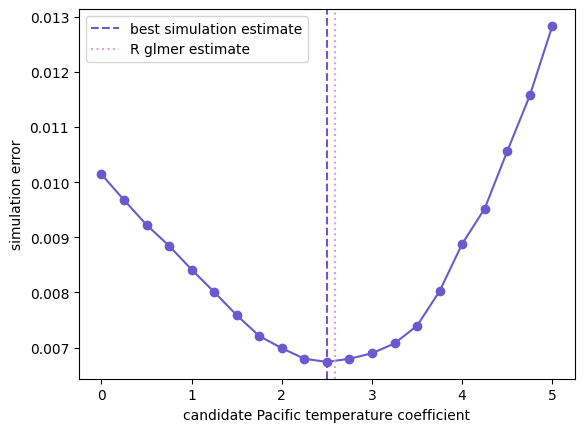

In [ ]:
# Plotting the two in order to get a visual understanding

plt.plot(candidates, scores, "o-", color = "slateblue")

plt.axvline(
    B1_estimated,linestyle="--",
    color = "slateblue",
    label="Best simulation estimate")

plt.axvline(
    2.58821,
    linestyle=":",
    color = "plum",
    label="R glmer estimate")

plt.xlabel("Candidate Pacific temperature coefficient")

plt.ylabel("Simulation error")

plt.legend()

plt.show()



# Shoutout:
### https://matplotlib.org/stable/gallery/color/named_colors.html
### https://matplotlib.org/stable/api/markers_api.html

This is how a coefficient using simulation based fitting could be estimated, if all other coefficients were known. It is noted that the simulated estimated value of the Pacific temperature coefficient is very close to the one we got using R's glmr function. This indicates that the estimated coefficients we obtainted from R should be okay.

------
# The work: Foward simulation
###Model validation: Does the model fit?

 *One complete simulated experiment to compare our model to the researchers' actual observations*


-----

Using the exact coefficients from our R code that used the glmer function, and doing the same thing that was previously described when we defined our `simulate_bleaching` function.

Now we are doing it for our model and then comparing it to the observed data. Our final figure looks at all the regions in order to be similar to Fig 4 which is presented in the article.

---



In [ ]:

def simulate_experiment(data, seed=1378): # Choosing the same seed for reproducibility

  # Same as before, we are keeping track of the seeds
    random = np.random.default_rng(seed)

    reef_effects = {}

    for reef in data["location_id"].unique():
        reef_effects[reef] = random.normal(0,reef_sd)
        # So again this random effect is being specified
        # Again, normal distribution around certain area involving the variance

    simulated = []
    probabilities = []

# We're using the same code, but now we have all our coefficients etc.
    for _, row in data.iterrows():

        region = row["region"]

# We are calling to known coefficients
        severe_sim, p = simulate_bleaching( # Forward simulation
            B0=B0[region],
            B1=B1[region],
            B2=B2[region],
            G=row["temp_c"],
            N=row["nino_c"],
            reef_effect=reef_effects[row["location_id"]],
            random=random
        )

        simulated.append(severe_sim) # We add our data to the necessary lists we want to then plot compare and plot.
        probabilities.append(p)

    result = pd.DataFrame({
        "location_id": data["location_id"].values,
        "region": data["region"].values,
        "year": data["year"].values,
        "observed": data["severe"].values,
        "predicted_probability": probabilities,
        "simulated": simulated
    })

    return result

In [ ]:
one_simulation = simulate_experiment(master)

display(one_simulation.head())

# Observed is our reality, simulated is what we got

,location_id,region,year,observed,predicted_probability,simulated
0,1,Australasia,1980,0,0.003460,0
1,1,Australasia,1981,0,0.009122,0
2,1,Australasia,1982,0,0.000606,0
3,1,Australasia,1983,0,0.004019,0
4,1,Australasia,1984,0,0.003094,0


In [ ]:
# Essentially a table instead since we want to plot it out
# We're aggregating the data now too

yearly_compare = (
    one_simulation
    .groupby(["region", "year"])
    .agg(
        observed=("observed", "mean"),
        simulated=("simulated", "mean"),
        predicted=("predicted_probability", "mean")
    )
    .reset_index()
)

print(yearly_compare)

            region  year  observed  simulated  predicted
0      Australasia  1980  0.000000   0.000000   0.004804
1      Australasia  1981  0.000000   0.000000   0.012632
2      Australasia  1982  0.000000   0.000000   0.000842
3      Australasia  1983  0.031250   0.000000   0.005579
4      Australasia  1984  0.000000   0.000000   0.004297
..             ...   ...       ...        ...        ...
143  West Atlantic  2012  0.000000   0.045455   0.103534
144  West Atlantic  2013  0.000000   0.181818   0.100955
145  West Atlantic  2014  0.000000   0.136364   0.127700
146  West Atlantic  2015  0.136364   0.136364   0.231755
147  West Atlantic  2016  0.000000   0.181818   0.185220

[148 rows x 5 columns]


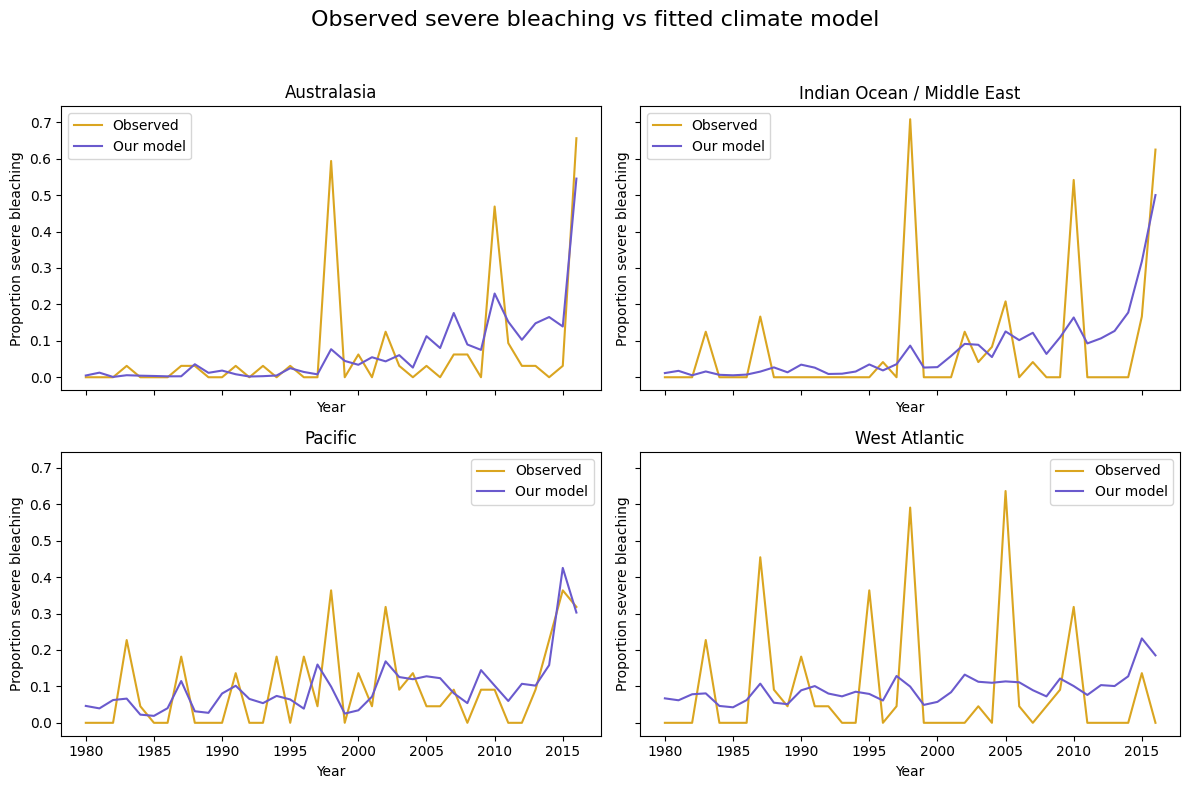

In [ ]:
# We are plotting our proportion of severe bleaching based on our one simulation against the actual data
regions = [
    "Australasia",
    "Indian Ocean / Middle East",
    "Pacific",
    "West Atlantic"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, region in zip(axes, regions):

    region_data = yearly_compare[
        yearly_compare["region"] == region
    ]

    ax.plot(
        region_data["year"],
        region_data["observed"],
        color = "goldenrod",
        label="Observed"
    )

    ax.plot(
        region_data["year"],
        region_data["predicted"],
        color = "slateblue",
        label="Our model"
    )

    ax.set_title(region)
    ax.set_xlabel("Year")
    ax.set_ylabel("Proportion severe bleaching")

    ax.legend()

fig.suptitle(
    "Observed severe bleaching vs fitted climate model",
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

So from what we see, our model is actually able to go up and down (which is what we wanted). The general trend upwards is also great to see since the researchers noted that too. Sometimes there are major spikes that our model does not reach, but we do still see it have its own little hills.

From our R work, we noticed that the Pacific region had the strongest significant correlations between our two climate predictors. The Nino 3.4 measurements are actually taken around that region so it is not surprising that these predictors help the model's accuracy for this region.

West Atlantic is sadly the least successful of them all, but the researchers had similar issues as well. Mentioned in the limitations, this region is affected by major hurricanes and water temperature fluctuations that are difficult to capture when working with anomaly means that are not even focused on this area.

Overall, we were pretty happy to see that the model could predict some of the ups and downs.

------
#The work: Comparing
###Did our model do what we wanted?

-----

We are comparing our model, the researchers' model, and the observed data now. We have the coefficients for the researcher's model from our R code as well because they did not include them in their paper (except for the Pacific region).

We do have to make a new function because the paper's model uses only Region and Time so the code below reflects that.

---

,location_id,region,year,observed,paper_probability,paper_simulated
0,1,Australasia,1980,0,0.007426,0
1,1,Australasia,1981,0,0.008138,0
2,1,Australasia,1982,0,0.008918,0
3,1,Australasia,1983,0,0.009772,0
4,1,Australasia,1984,0,0.010706,0


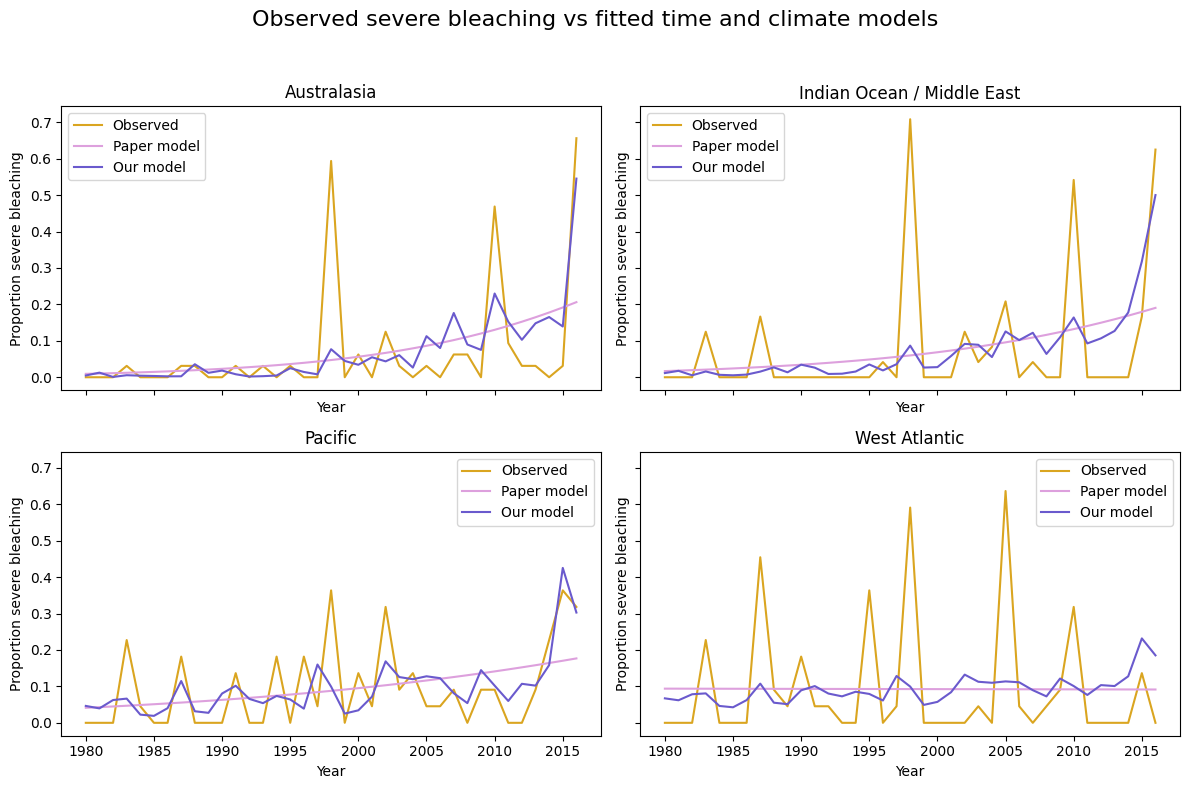

In [ ]:

# Since the paper doesn't have coefficients for all their regions, we use our own (from R)

paper_B0 = {
    "Australasia": -4.7034713,
    "Indian Ocean / Middle East": -4.0422950,
    "Pacific": -3.1861919,
    "West Atlantic": -2.2890136
}

paper_B1 = {
    "Australasia": 0.0922876,
    "Indian Ocean / Middle East": 0.0728153,
    "Pacific": 0.0448057,
    "West Atlantic": -0.0007754
}

paper_reef_sd = 0.19343

def simulate_paper_experiment(data, seed=1378):

    random = np.random.default_rng(seed)

    reef_effects = {}

    for reef in data["location_id"].unique():
        reef_effects[reef] = random.normal(
            0,
            paper_reef_sd
        )

    simulated = []
    probabilities = []

    for _, row in data.iterrows():

        region = row["region"]

        # Paper predictor
        t = row["year"] - 1980

        Z = ( paper_B0[region] + paper_B1[region] * t + reef_effects[row["location_id"]] ) #paper's model!!!!!!!

        p = probability(Z)

        severe_sim = random.binomial(
            1,
            p
        )

        simulated.append(severe_sim)
        probabilities.append(p)

    result = pd.DataFrame({
        "location_id": data["location_id"].values,
        "region": data["region"].values,
        "year": data["year"].values,
        "observed": data["severe"].values,
        "paper_probability": probabilities,
        "paper_simulated": simulated
    })

    return result

paper_one_simulation = simulate_paper_experiment(master)

display(paper_one_simulation.head())

paper_yearly_compare = (
    paper_one_simulation
    .groupby(["region", "year"])
    .agg(
        observed=("observed", "mean"),
        simulated=("paper_simulated", "mean"),
        predicted=("paper_probability", "mean")
    )
    .reset_index()
)

regions = [
    "Australasia",
    "Indian Ocean / Middle East",
    "Pacific",
    "West Atlantic"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, region in zip(axes, regions):

    climate_data = yearly_compare[
        yearly_compare["region"] == region
    ]

    paper_data = paper_yearly_compare[
        paper_yearly_compare["region"] == region
    ]

    # Actual observed proportions
    ax.plot(
        climate_data["year"],
        climate_data["observed"],
        color="goldenrod",
        label="Observed"
    )

    # Hughes et al. time-model fitted probability
    ax.plot(
        paper_data["year"],
        paper_data["predicted"],
        color="plum",
        label="Paper model"
    )

    # Our climate model fitted probability
    ax.plot(
        climate_data["year"],
        climate_data["predicted"],
        color="slateblue",
        label="Our model"
    )

    ax.set_title(region)
    ax.set_xlabel("Year")
    ax.set_ylabel("Proportion severe bleaching")
    ax.legend()

fig.suptitle(
    "Observed severe bleaching vs fitted time and climate models",
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

As we spoke of earlier, we wanted our model to predict the fluctuations in severe bleaching cases a bit better than the researchers' model. Their model is pretty straightforward as they essentially had a regional baseline ($\beta_0$) and each region then had a stable effect ($\beta_1$) on time as it continued.

We were quite happy to see that while their model essentially failed for the West Atlantic, ours did manage to have some oscillations and a slight increase. It is likely not significant, but having some variation for a difficult region to predict was nice to see.

**Why do we see a straight-ish like for the paper?**

They use time (years since 1980) as one of their fixed effects. They have the region as an intercept ( a baseline) and then the "slope" time provides. They simply are saying that as calendar time passes, the underlying probability of severe bleaching tends to rise.

They imply that temperature is a contributing factor and generate a figure and do quite a bit of work to display the data, but their model doesn't use it. So this is why we see a generally straight line. They still have the random effect but their fixed effects predict more of a long term trend that they insinuated through the figures in their paper of their observations and the climate data. Therefore we see a stable probability change.


------

#The work: Comparing
###Scoring our model and the researchers' model

-----

The simple graph below is a comparison of the AIC. It was done in our R notebook (we only pulled the values here) and is explained further there, but the idea is that a lower AIC score suggests that the model is better.

We also tried out another model initially in which we did not use the Nino 3.4 anomaly, and only used the global temperature anomaly. The Nino 3.4 data was only significantly correlated with the Pacific region (because it is measured right around the Pacific reefs) but it still improved the model despite our expectation that it would be made worse. Although the coefficients vary for this variable, we thought it might be barely affecting everything but the Pacific region (where it is helping predictions) and is subsequently making the model slightly better.

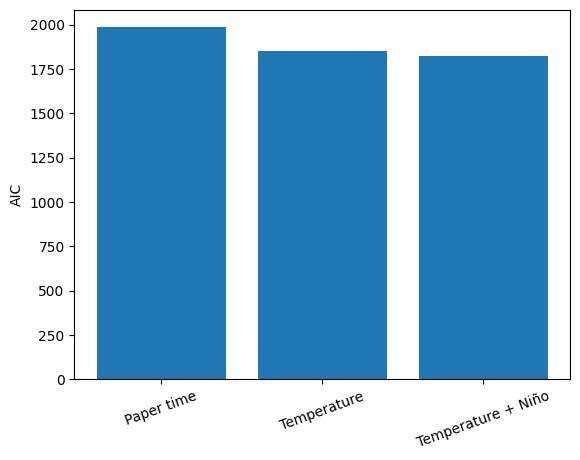

In [ ]:
models = [
    "Paper time",
    "Temperature",
    "Temperature + Niño"
]

aic = [
    1984.8,
    1850.5,
    1822.1
]

plt.bar(models, aic)
plt.ylabel("AIC")
plt.xticks(rotation=20)
plt.show()

------

#The work: Forward simulations and uncertainty

###What range of bleaching outcomes can our fitted model generate?


-----

We are doing the forward simulation many times to try and see the range that can be predicted with this model. Our coefficients stay the same but our random effect does not. The actual prediction (severe bleaching, S, or no severe bleaching) will also change.

For each region and year, we used these simulations to calculate a median predicted bleaching proportion and a central 95% simulation interval (the middle of the data). We then compared the actual observed bleaching proportions with this interval to evaluate whether the model generated a realistic range of historical bleaching outcomes.

So we quantified uncertainty by repeatedly simulating the model. Because reef effects and individual bleaching outcomes are stochastic, each run produces slightly different yearly bleaching proportions. The spread across 400 runs gives a predictive interval showing the range of outcomes the model could generate.


In [ ]:
# Monte carlo uncertainty (Shoutout the Session 8 exercise)

all_runs = []

for s in range(400):

    sim = simulate_experiment(
        master,
        seed = 1378 + s # We are no longer sticking to 1378, we continue on to next seed. So our random effect will be recalculated
    )

    yearly = (
        sim
        .groupby(["region", "year"])["simulated"]
        .mean()
        .reset_index()
    )

    yearly["simulation"] = s

    all_runs.append(yearly)

all_runs = pd.concat(
    all_runs,
    ignore_index=True
)

In [ ]:
simulation_summary = (
    all_runs
    .groupby(["region", "year"])["simulated"]
    .agg(
        median="median",
        lower=lambda x: x.quantile(0.025),
        upper=lambda x: x.quantile(0.975)
    )
    .reset_index()
)

# We're using the 95% middle of the data so we take 2.5 off the top and bottom
# These are our upper and lower quantiles

Looking at each region again but with this interval now:

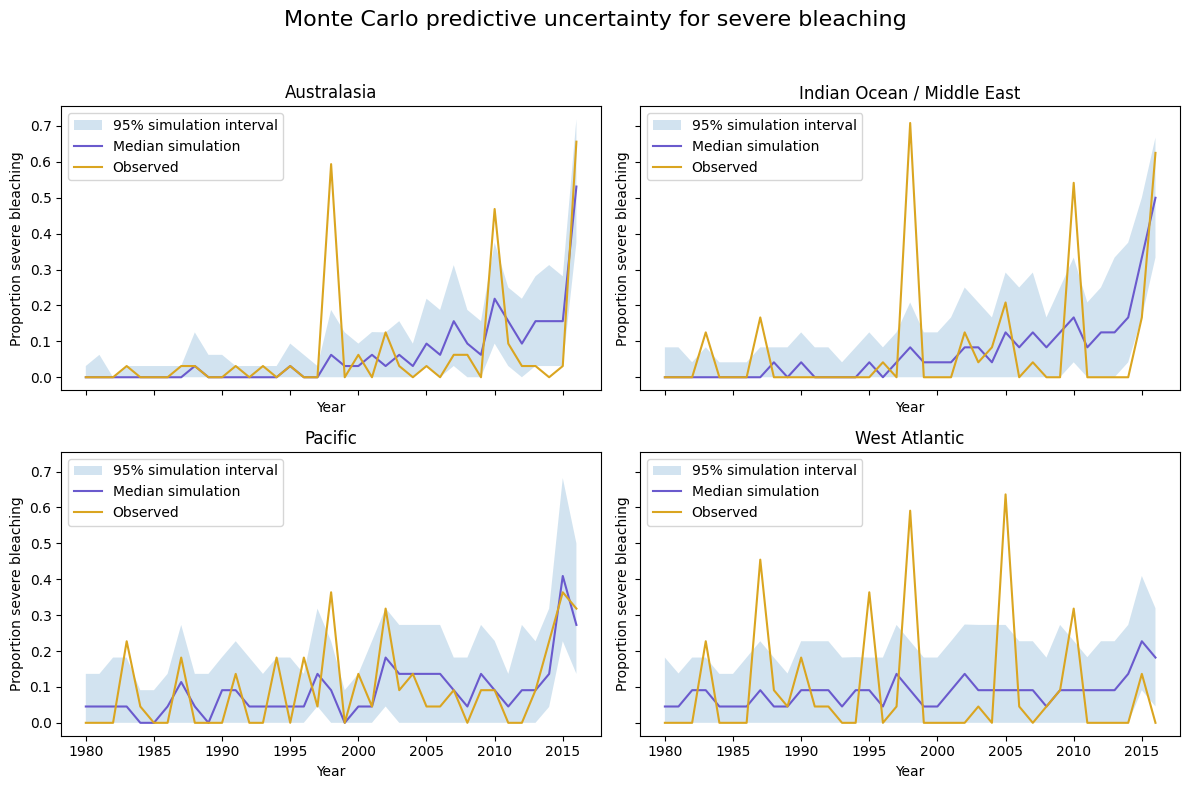

In [ ]:
# Checking what fraction of the actual observed region/year bleaching proportions
# fell inside our model’s 95% predictive interval.

regions = [
    "Australasia",
    "Indian Ocean / Middle East",
    "Pacific",
    "West Atlantic"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for ax, region in zip(axes, regions):

    # Monte Carlo summary for this region
    sim = simulation_summary[
        simulation_summary["region"] == region
    ]

    # Observed yearly proportions
    obs = (
        master[master["region"] == region]
        .groupby("year")["severe"]
        .mean()
    )

    # 95% predictive simulation interval
    ax.fill_between(
        sim["year"],
        sim["lower"],
        sim["upper"],
        alpha=0.2,
        label="95% simulation interval"
    )

    # Median across the 400 simulations
    ax.plot(
        sim["year"],
        sim["median"],
        color = "slateblue",
        label="Median simulation"
    )

    # Actual observed bleaching
    ax.plot(
        obs.index,
        obs.values,
        color = "goldenrod",
        label="Observed"
    )

    ax.set_title(region)
    ax.set_xlabel("Year")
    ax.set_ylabel("Proportion severe bleaching")
    ax.legend()

fig.suptitle(
    "Monte Carlo predictive uncertainty for severe bleaching",
    fontsize=16
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()

Now for the next part we are asking:

**How often did the actual observed bleaching proportion fall within the range our model commonly generates?**

In [ ]:
# Quantification
observed_yearly = (
    master
    .groupby(["region", "year"])["severe"]
    .mean()
    .reset_index(name="observed")
)

check = observed_yearly.merge(
    simulation_summary,
    on=["region", "year"]
)

check["inside_interval"] = (
    (check["observed"] >= check["lower"])
    &
    (check["observed"] <= check["upper"])
)

coverage = (
    check
    .groupby("region")["inside_interval"]
    .mean()
)

print(coverage)

# What this is telling us is that about 81-91% of the time, the observed data is within this interval which our model generates.

region
Australasia                   0.918919
Indian Ocean / Middle East    0.864865
Pacific                       0.918919
West Atlantic                 0.810811
Name: inside_interval, dtype: float64




This last bit here tells us how often the observed data is actually within this range we generated. The values range from 0.81-0.91 which tells us that our model is pretty limited. We were quite surprised that Australasia and the Pacific are identical but when we looked at the figures it seemed alright (also it means that it was within the interval for 34 out of the 37 years).



------
#Conclusion

---

Hughes et al. modeled the temporal increase in severe bleaching using Region and Time as the main fixed predictors. Our model replaces this abstract temporal trend with measured global temperature anomaly and Niño 3.4 anomaly. This asks whether observed climate variation can generate bleaching patterns similar to those reported in the paper.

While time indicated that bleaching changed, the climate variables could propose an explanation for why it changed.

We are still limited by what variables we are looking at as there are so many to actually consider. Our use of annual means also hides data that could show why a mass bleaching event occurred if there was a sudden short term spike over a few months hidden by the rest. Regardless, it was nice to be able to find data online and use it to try and understand an environmental concern better.

Thank you!